# Problem 2: Pixel Connectivity Analysis (4, 8, and m- Connectivity)

Task: Implement a Python function using NumPy to identify if a path exists between two pixel coordinates (p, q) based on 4-connectivity, 8-connectivity, and m-connectivity (mixed connectivity).

• 4-Neighbors (N4(p)): Two pixels are 4-connected if q ∈ N4(p).

• 8-Neighbors (N8(p)): Two pixels are 8-connected if q ∈ N8(p).

• m-Connectivity: Designed to eliminate multiple paths that occur in 8-connectivity.
Two pixels p and q with values from V are m-connected if:
1. q ∈ N4(p), OR
2. q ∈ ND(p) AND the set N4(p) ∩ N4(q) has no pixels whose values are in V

In [167]:
from matplotlib import pyplot as plt
import numpy as np
from collections import deque

In [1]:
class Img:
    Nadj = [(-1, 0), (1, 0), (0, -1), (0, 1)]   
    Ndiag = [(-1, -1), (-1, 1), (1, -1), (1, 1)]

    def __init__(self, img):
        self.img = img
        self.rows, self.cols = img.shape

    def show(self):
        plt.imshow(self.img, cmap='binary')
        plt.show()

    def get_neighbors(self, P, conn_type, V={1}):
        r, c = P
        neighbors = []

        if conn_type == 4:
            for dr, dc in self.Nadj:
                nr, nc = r + dr, c + dc
                if 0 <= nr < self.rows and 0 <= nc < self.cols:
                    if self.img[nr, nc] in V:
                        neighbors.append((nr, nc))

        elif conn_type == 8:
            for dr, dc in self.Nadj + self.Ndiag:
                nr, nc = r + dr, c + dc
                if 0 <= nr < self.rows and 0 <= nc < self.cols:
                    if self.img[nr, nc] in V:
                        neighbors.append((nr, nc))

        elif conn_type == 'm':
            # First include 4-neighbors
            for dr, dc in self.Nadj:
                nr, nc = r + dr, c + dc
                if 0 <= nr < self.rows and 0 <= nc < self.cols:
                    if self.img[nr, nc] in V:
                        neighbors.append((nr, nc))

            for dr, dc in self.Ndiag:
                nr, nc = r + dr, c + dc
                if 0 <= nr < self.rows and 0 <= nc < self.cols:
                    if self.img[nr, nc] in V:
                        common = []
                        for adr, adc in self.Nadj:
                            ar, ac = r + adr, c + adc
                            if 0 <= ar < self.rows and 0 <= ac < self.cols:
                                if (abs(ar - nr) + abs(ac - nc)) == 1:
                                    if self.img[ar, ac] in V:
                                        common.append((ar, ac))

                        if len(common) == 0:
                            neighbors.append((nr, nc))

        return neighbors

    def bfs(self, start, end, conn_type, V={1}):
        if self.img[start] not in V or self.img[end] not in V:
            return False

        visited = set()
        queue = deque([start])
        visited.add(start)

        while queue:
            current = queue.popleft()

            if current == end:
                return True

            for neighbor in self.get_neighbors(current, conn_type, V):
                if neighbor not in visited:
                    visited.add(neighbor)
                    queue.append(neighbor)

        return False

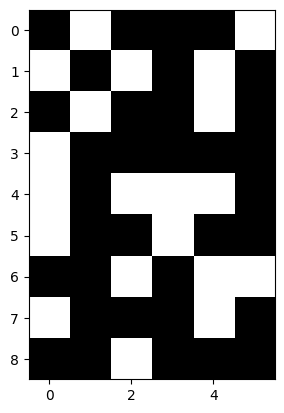

4-connectivity: False
8-connectivity: True
m-connectivity: True


In [ ]:
np.random.seed(8)
img_arr = np.random.randint(0, 2, size=(9, 6))

img = Img(img_arr)
img.show()

start = (0, 0)
end = (8, 5)

print("4-connectivity:", img.bfs(start, end, 4))
print("8-connectivity:", img.bfs(start, end, 8))
print("m-connectivity:", img.bfs(start, end, 'm'))

In [2]:
import numpy as np
from collections import deque

N4 = [(-1,0),(1,0),(0,-1),(0,1)]
ND = [(-1,-1),(-1,1),(1,-1),(1,1)]

def nbrs(img, p, t, V={1}):
    R, C = img.shape
    r, c = p
    out = []

    # 4-connectivity
    for dr, dc in N4:
        x, y = r+dr, c+dc
        if 0 <= x < R and 0 <= y < C and img[x,y] in V:
            out.append((x,y))

    if t == 4:
        return out

    # 8-connectivity
    if t == 8:
        for dr, dc in ND:
            x, y = r+dr, c+dc
            if 0 <= x < R and 0 <= y < C and img[x,y] in V:
                out.append((x,y))
        return out

    # m-connectivity
    for dr, dc in ND:
        x, y = r+dr, c+dc
        if 0 <= x < R and 0 <= y < C and img[x,y] in V:
            if not any(
                0 <= r+a < R and 0 <= c+b < C and img[r+a,c+b] in V
                and abs((r+a)-x) + abs((c+b)-y) == 1
                for a,b in N4
            ):
                out.append((x,y))
    return out


def path(img, s, e, t, V={1}):
    if img[s] not in V or img[e] not in V:
        return False

    q, seen = deque([s]), {s}

    while q:
        p = q.popleft()
        if p == e:
            return True
        for n in nbrs(img, p, t, V):
            if n not in seen:
                seen.add(n)
                q.append(n)
    return False

In [3]:
np.random.seed(8)
img = np.random.randint(0,2,(9,6))

s, e = (0,0), (8,5)

print("4:", path(img, s, e, 4))
print("8:", path(img, s, e, 8))
print("m:", path(img, s, e, 'm'))

4: False
8: True
m: True


In [12]:
r, c = 5, 7
s, t = 3, 4
x, y = np.meshgrid(np.arange(r), np.arange(c), indexing='ij')
D4 = np.abs(x-s) + np.abs(y-t)
D8 = np.maximum(np.abs(x-s), np.abs(y-t))
print("D4 Distance Map:", D4)
print("D8 Distance Map:", D8)

D4 Distance Map: [[7 6 5 4 3 4 5]
 [6 5 4 3 2 3 4]
 [5 4 3 2 1 2 3]
 [4 3 2 1 0 1 2]
 [5 4 3 2 1 2 3]]
D8 Distance Map: [[4 3 3 3 3 3 3]
 [4 3 2 2 2 2 2]
 [4 3 2 1 1 1 2]
 [4 3 2 1 0 1 2]
 [4 3 2 1 1 1 2]]
